# Patient Similarity Graph GAT - CVD Risk Prediction

Extends the ResNet18 CNN baseline into a patient similarity graph classified with a Graph Attention Network (GAT). Requires `best_model.pt` and the patient ID split CSVs from the CNN notebook.

Pipeline:
1. Load the trained ResNet18, extract its 512-dim penultimate-layer embedding for every image (both eyes)
2. Average left/right eye embeddings per patient to get one vector per patient
3. Build a patient similarity graph: nodes = patients, node features = [image embedding + age_norm + gender], edges = k-nearest-neighbors by combined (embedding + age/gender) distance
4. Train a GAT for semi-supervised node classification (thickened vs normal)
5. Evaluate on the same test-set patients as the CNN baseline


## 1. Setup

In [2]:
import os, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.data import Data
from torchvision import transforms, models
from torch.utils.data import Dataset, DataLoader
from PIL import Image

from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, roc_auc_score, confusion_matrix, classification_report, roc_curve

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

/opt/anaconda3/envs/pbl_env/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Using device: cpu


In [3]:
try:
    import torch_geometric
    from torch_geometric.nn import GATConv
    from torch_geometric.data import Data
    print("torch_geometric already installed:", torch_geometric.__version__)
except ImportError:
    print("torch_geometric not found — install with: pip install torch_geometric")


torch_geometric already installed: 2.8.0.post1


## 2. Paths (same as the CNN baseline notebook)

In [ ]:
CNN_CHECKPOINT = "best_model.pt"

IMG_SIZE = 224
K_NEIGHBORS = 15
EMBED_WEIGHT = 0.6

## 3. Load metadata


In [5]:
with open(JSON_PATH, "r") as f:
    meta = json.load(f)

rows = []
for patient_id, record in meta.items():
    label = record["label"]
    for side_key, side_name in [("left_eye", "L"), ("right_eye", "R")]:
        fname = record.get(side_key)
        if not fname:
            continue
        fpath = os.path.join(DATA_DIR, fname)
        if not os.path.exists(fpath):
            continue
        rows.append({
            "patient_id": patient_id,
            "filepath": fpath,
            "side": side_name,
            "true_age": record.get("True_age"),
            "age_norm": record.get("age"),
            "gender": record.get("gender"),
            "thickness": record.get("thickness"),
            "label": label
        })

df = pd.DataFrame(rows)
print(f"Total image rows: {len(df)}  |  Unique patients: {df.patient_id.nunique()}")


Total image rows: 5806  |  Unique patients: 2903


## 4. Reload train/val/test patient split


In [ ]:
df["patient_id"] = df["patient_id"].astype(str).str.strip()
print(f"Train: {len(train_ids)} | Val: {len(val_ids)} | Test: {len(test_ids)}")

overlap_test = set(test_ids) & set(df["patient_id"])
overlap_val  = set(val_ids)  & set(df["patient_id"])
print(f"Overlap — val: {len(overlap_val)}, test: {len(overlap_test)}")
if len(overlap_test) == 0:
    print("Sample df ID:", df['patient_id'].unique()[:3].tolist())
    print("Sample test ID:", test_ids[:3])

## 5. Load the trained CNN and extract per-image embeddings

Strips the final classification layer so the model outputs the 512-dim penultimate feature vector.


In [7]:
resnet = models.resnet18(weights=None)
resnet.fc = nn.Linear(resnet.fc.in_features, 2)
resnet.load_state_dict(torch.load(CNN_CHECKPOINT, map_location=device))
resnet.fc = nn.Identity()   # strip classifier; outputs 512-dim embedding
resnet = resnet.to(device)
resnet.eval()
print("Loaded CNN backbone for embedding extraction.")


Loaded CNN backbone for embedding extraction.


In [8]:
embed_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

class ImageOnlyDataset(Dataset):
    def __init__(self, dataframe, transform):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform
    def __len__(self):
        return len(self.df)
    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img = Image.open(row["filepath"]).convert("RGB")
        img = self.transform(img)
        return img, idx  # return row index so we can map embeddings back

embed_ds = ImageOnlyDataset(df, embed_transform)
embed_loader = DataLoader(embed_ds, batch_size=32, shuffle=False, num_workers=0)

all_embeddings = np.zeros((len(df), 512), dtype=np.float32)

with torch.no_grad():
    for imgs, idxs in embed_loader:
        imgs = imgs.to(device)
        feats = resnet(imgs).cpu().numpy()
        all_embeddings[idxs.numpy()] = feats

print("Extracted embeddings shape:", all_embeddings.shape)


Extracted embeddings shape: (5806, 512)


## 6. Aggregate to one embedding per patient (average left/right eye)

In [9]:
df["embed_idx"] = np.arange(len(df))

patient_records = []
for pid, group in df.groupby("patient_id"):
    idxs = group["embed_idx"].values
    avg_embedding = all_embeddings[idxs].mean(axis=0)
    patient_records.append({
        "patient_id": pid,
        "embedding": avg_embedding,
        "age_norm": group["age_norm"].iloc[0],
        "gender": group["gender"].iloc[0],
        "label": group["label"].iloc[0],
        "thickness": group["thickness"].iloc[0],
    })

patients_df = pd.DataFrame(patient_records)
print(f"Total patient nodes: {len(patients_df)}")
patients_df.head()


Total patient nodes: 2903


,patient_id,embedding,age_norm,gender,label,thickness
0,100464002,"[0.72087824, 0.8962835, 1.0450007, 1.2131737, ...",0.575342,1,1,1.1
1,100468003,"[1.7287598, 0.8851168, 1.3138181, 1.4830079, 0...",0.589041,0,1,1.0
2,10323005,"[0.8250252, 0.93311024, 0.6691812, 1.2770863, ...",0.534247,1,0,0.8
3,104191003,"[1.0329533, 0.93559855, 0.66128427, 1.3928497,...",0.452055,1,0,0.7
4,10510005,"[0.8583496, 1.2672498, 1.3110267, 1.3392332, 0...",0.671233,0,1,1.1


## 7. Build the patient similarity graph

Each patient is connected to its k-nearest neighbors under a combined distance: `EMBED_WEIGHT * (image embedding distance) + (1 - EMBED_WEIGHT) * (age/gender distance)`. Both components are standardized before combining.


In [10]:
embed_matrix = np.stack(patients_df["embedding"].values)
embed_matrix_scaled = StandardScaler().fit_transform(embed_matrix)

clinical_matrix = patients_df[["age_norm", "gender"]].values.astype(np.float32)
clinical_matrix_scaled = StandardScaler().fit_transform(clinical_matrix)

combined_matrix = np.concatenate([
    np.sqrt(EMBED_WEIGHT) * embed_matrix_scaled,
    np.sqrt(1 - EMBED_WEIGHT) * clinical_matrix_scaled
], axis=1)

nbrs = NearestNeighbors(n_neighbors=K_NEIGHBORS + 1).fit(combined_matrix)
distances, indices = nbrs.kneighbors(combined_matrix)

neighbor_sets = [set(indices[i][1:]) for i in range(len(patients_df))]
edge_list, weight_list = [], []
for i in range(len(patients_df)):
    for pos, j in enumerate(indices[i][1:]):
        if i not in neighbor_sets[j]:   # mutual k-NN only
            continue
        d = distances[i][pos + 1]
        w = 1.0 / (1.0 + d)
        edge_list.append((i, j)); weight_list.append(w)
        edge_list.append((j, i)); weight_list.append(w)

edge_index = torch.tensor(edge_list, dtype=torch.long).t().contiguous()
edge_attr = torch.tensor(weight_list, dtype=torch.float).unsqueeze(-1)
print(f"Graph: {len(patients_df)} nodes, {edge_index.shape[1]} edges (mutual k={K_NEIGHBORS})")

Graph: 2903 nodes, 32592 edges (mutual k=15)


## 8. Assemble node features, labels, and train/val/test masks

In [ ]:
node_features = np.concatenate([embed_matrix, clinical_matrix], axis=1)
node_features = StandardScaler().fit_transform(node_features)

x = torch.tensor(node_features, dtype=torch.float)
y = torch.tensor(patients_df["label"].values, dtype=torch.long)

pid_to_idx = {pid: i for i, pid in enumerate(patients_df["patient_id"])}
train_mask = torch.zeros(len(patients_df), dtype=torch.bool)
val_mask   = torch.zeros(len(patients_df), dtype=torch.bool)
test_mask  = torch.zeros(len(patients_df), dtype=torch.bool)
print(f"Train: {train_mask.sum().item()} | Val: {val_mask.sum().item()} | Test: {test_mask.sum().item()}")
assert test_mask.sum().item() > 0, "test_mask empty — fix cell 10's ID mismatch first."
assert val_mask.sum().item() > 0, "val_mask empty — fix cell 10's ID mismatch first."

graph_data = Data(x=x, edge_index=edge_index, edge_attr=edge_attr, y=y,
                   train_mask=train_mask, val_mask=val_mask, test_mask=test_mask).to(device)

## 9. GAT model

In [12]:
class PatientGAT(nn.Module):
    def __init__(self, in_dim, hidden_dim, heads, num_classes, dropout=0.5):
        super().__init__()
        self.dropout = dropout
        self.gat1 = GATConv(in_dim, hidden_dim, heads=heads, dropout=dropout, edge_dim=1)
        self.bn1 = nn.BatchNorm1d(hidden_dim * heads)
        self.gat2 = GATConv(hidden_dim * heads, num_classes, heads=1, concat=False, dropout=dropout, edge_dim=1)
        self.skip_proj = nn.Linear(in_dim, hidden_dim * heads)

    def forward(self, x, edge_index, edge_attr, return_attention=False):
        x_in = x
        x = F.dropout(x, p=self.dropout, training=self.training)
        h1, (edge_idx1, alpha1) = self.gat1(x, edge_index, edge_attr=edge_attr, return_attention_weights=True)
        h1 = self.bn1(h1); h1 = F.elu(h1)
        h1 = h1 + self.skip_proj(x_in)
        h1 = F.dropout(h1, p=self.dropout, training=self.training)
        out, (edge_idx2, alpha2) = self.gat2(h1, edge_index, edge_attr=edge_attr, return_attention_weights=True)
        if return_attention:
            return out, (edge_idx1, alpha1), (edge_idx2, alpha2)
        return out

model = PatientGAT(in_dim=x.shape[1], hidden_dim=GAT_HIDDEN, heads=GAT_HEADS,
                    num_classes=2, dropout=GAT_DROPOUT).to(device)
class_counts = torch.bincount(graph_data.y[graph_data.train_mask])
class_weights = 1.0 / torch.sqrt(class_counts.float())
class_weights = (class_weights / class_weights.sum() * 2).to(device)
criterion = nn.CrossEntropyLoss(weight=class_weights)

## 10. Training loop

In [ ]:
def evaluate(mask):
    model.eval()
    with torch.no_grad():
        out = model(graph_data.x, graph_data.edge_index, graph_data.edge_attr)
        loss = criterion(out[mask], graph_data.y[mask]).item()
        preds = out[mask].argmax(dim=1)
        acc = (preds == graph_data.y[mask]).float().mean().item()
    return loss, acc

## 11. Training curves

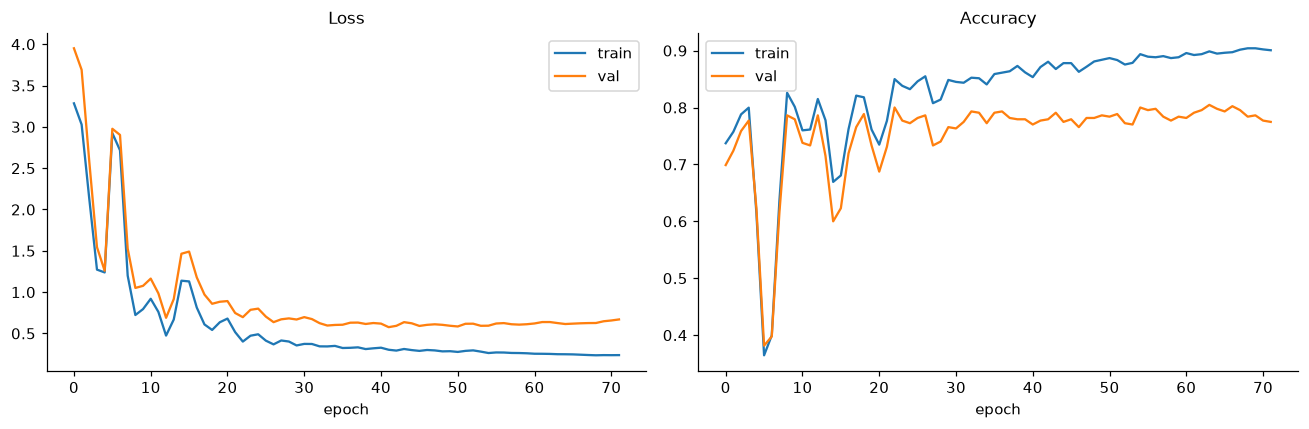

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history["train_loss"], label="train")
axes[0].plot(history["val_loss"], label="val")
axes[0].set_title("Loss"); axes[0].set_xlabel("epoch"); axes[0].legend()

axes[1].plot(history["train_acc"], label="train")
axes[1].plot(history["val_acc"], label="val")
axes[1].set_title("Accuracy"); axes[1].set_xlabel("epoch"); axes[1].legend()
plt.tight_layout()
plt.show()


## 12. Test set evaluation


In [16]:
model.load_state_dict(torch.load("best_gat_model.pt"))
model.eval()
with torch.no_grad():
    out = model(graph_data.x, graph_data.edge_index, graph_data.edge_attr)
    all_probs = F.softmax(out, dim=1)[:, 1].cpu().numpy()

test_idx = graph_data.test_mask.cpu().numpy()
val_idx = graph_data.val_mask.cpu().numpy()
y_all = graph_data.y.cpu().numpy()

y_true_val, y_prob_val = y_all[val_idx], all_probs[val_idx]
y_true, y_prob = y_all[test_idx], all_probs[test_idx]

from sklearn.metrics import f1_score

best_thresh_f1, best_f1 = 0.5, -1
for t in np.arange(0.20, 0.81, 0.01):
    preds_t = (y_prob_val >= t).astype(int)
    f1_t = f1_score(y_true_val, preds_t)
    if f1_t > best_f1:
        best_f1, best_thresh_f1 = f1_t, t


print(f"F1-tuned threshold:   {best_thresh_f1:.2f} (val F1={best_f1:.4f})")
y_pred = (y_prob >= best_thresh_f1).astype(int)
acc = accuracy_score(y_true, y_pred)
auc = roc_auc_score(y_true, y_prob)

print(f"Test Accuracy: {acc:.4f} | Test AUC-ROC: {auc:.4f}")

F1-tuned threshold:   0.30 (val F1=0.8648)
Test Accuracy: 0.7798 | Test AUC-ROC: 0.8195


In [17]:
model.load_state_dict(torch.load("best_gat_model.pt"))
model.eval()
with torch.no_grad():
    out = model(graph_data.x, graph_data.edge_index, graph_data.edge_attr)
    all_probs = F.softmax(out, dim=1)[:, 1].cpu().numpy()

test_idx = graph_data.test_mask.cpu().numpy()
val_idx = graph_data.val_mask.cpu().numpy()
y_all = graph_data.y.cpu().numpy()

y_true_val, y_prob_val = y_all[val_idx], all_probs[val_idx]
y_true, y_prob = y_all[test_idx], all_probs[test_idx]

# Threshold tuning with a sensitivity floor
MIN_SENSITIVITY = 0.85
best_thresh, best_acc = 0.5, 0
for t in np.arange(0.20, 0.81, 0.01):
    preds_t = (y_prob_val >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true_val, preds_t).ravel()
    sens = tp / (tp + fn) if (tp + fn) else 0
    if sens < MIN_SENSITIVITY:
        continue
    a = accuracy_score(y_true_val, preds_t)
    if a > best_acc:
        best_acc, best_thresh = a, t

print(f"Threshold with sensitivity >= {MIN_SENSITIVITY}: {best_thresh:.2f} (val acc: {best_acc:.4f})")

y_pred = (y_prob >= best_thresh).astype(int)
acc = accuracy_score(y_true, y_pred)
auc = roc_auc_score(y_true, y_prob)

tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
sensitivity = tp / (tp + fn)
specificity = tn / (tn + fp)
ppv = tp / (tp + fp)
npv = tn / (tn + fn)
f1 = 2 * (ppv * sensitivity) / (ppv + sensitivity)
youden_j = sensitivity + specificity - 1
balanced_acc = (sensitivity + specificity) / 2

print(f"\nGAT Test Accuracy: {acc:.4f}")
print(f"GAT Test AUC-ROC:  {auc:.4f}")
print(f"Sensitivity:       {sensitivity:.4f}")

Threshold with sensitivity >= 0.85: 0.30 (val acc: 0.8023)

GAT Test Accuracy: 0.7798
GAT Test AUC-ROC:  0.8195
Sensitivity:       0.8864


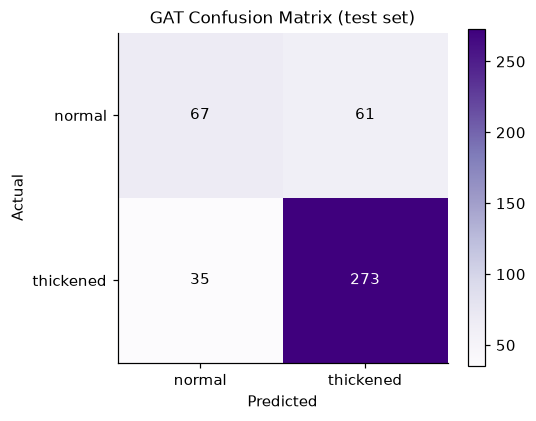

In [18]:
cm = confusion_matrix(y_true, y_pred)
fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks([0, 1]); ax.set_xticklabels(["normal", "thickened"])
ax.set_yticks([0, 1]); ax.set_yticklabels(["normal", "thickened"])
ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha="center", va="center",
                color="white" if cm[i, j] > cm.max()/2 else "black")
plt.title("GAT Confusion Matrix (test set)")
plt.colorbar(im)
plt.tight_layout()
plt.show()


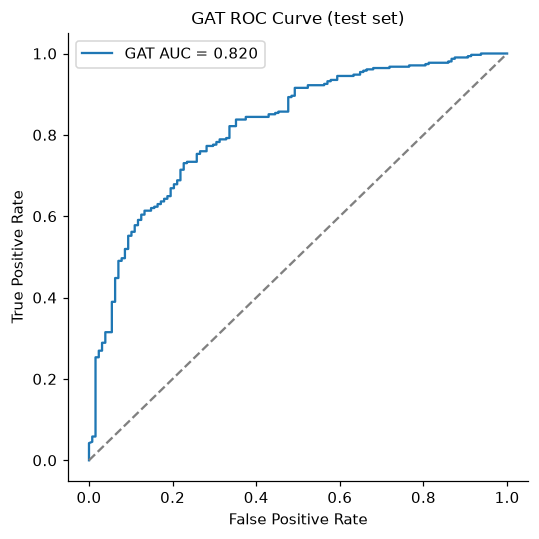

In [19]:
fpr, tpr, _ = roc_curve(y_true, y_prob)
plt.figure(figsize=(5, 5))
plt.plot(fpr, tpr, label=f"GAT AUC = {auc:.3f}")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("GAT ROC Curve (test set)")
plt.legend()
plt.tight_layout()
plt.show()


## 13. Attention weight inspection

Extracts which neighbour edges the model attended to most strongly for a sample of test patients.


In [20]:
model.eval()
with torch.no_grad():
    _, (edge_idx1, alpha1), _ = model(graph_data.x, graph_data.edge_index, graph_data.edge_attr, return_attention=True)

# alpha1 shape: [num_edges, num_heads] - average across heads for edge importance
edge_importance = alpha1.mean(dim=1).cpu().numpy()
edge_src = edge_idx1[0].cpu().numpy()
edge_dst = edge_idx1[1].cpu().numpy()

# Look at one example test patient
example_test_idx = np.where(test_idx)[0][0]
example_pid = patients_df.iloc[example_test_idx]["patient_id"]

mask = edge_dst == example_test_idx
neighbor_srcs = edge_src[mask]
neighbor_importance = edge_importance[mask]

top_order = np.argsort(-neighbor_importance)[:5]
print(f"Patient {example_pid} (test set): top attended neighbors")
for rank, i in enumerate(top_order):
    neighbor_pid = patients_df.iloc[neighbor_srcs[i]]["patient_id"]
    neighbor_label = patients_df.iloc[neighbor_srcs[i]]["label"]
    print(f"  {rank+1}. Patient {neighbor_pid} (label={neighbor_label}), attention weight={neighbor_importance[i]:.4f}")


Patient 100464002 (test set) -- top attended neighbors:
  1. Patient 100464002 (label=1), attention weight=0.3693
  2. Patient 135301003 (label=1), attention weight=0.1830
  3. Patient 135301003 (label=1), attention weight=0.1830
  4. Patient 469984004 (label=1), attention weight=0.1323
  5. Patient 469984004 (label=1), attention weight=0.1323


In [21]:
# Bootstrap 95% CI for AUC-ROC
n_bootstraps = 1000
rng = np.random.RandomState(SEED)
bootstrapped_aucs_gat = []

for i in range(n_bootstraps):
    indices = rng.randint(0, len(y_prob), len(y_prob))
    if len(np.unique(y_true[indices])) < 2:
        continue
    score = roc_auc_score(y_true[indices], y_prob[indices])
    bootstrapped_aucs_gat.append(score)

ci_lower = np.percentile(bootstrapped_aucs_gat, 2.5)
ci_upper = np.percentile(bootstrapped_aucs_gat, 97.5)
print(f"GAT AUC-ROC: {auc:.4f}  (95% CI: {ci_lower:.4f} - {ci_upper:.4f}, n_bootstrap={len(bootstrapped_aucs_gat)})")

np.save("gat_bootstrap_aucs.npy", np.array(bootstrapped_aucs_gat))

GAT AUC-ROC: 0.8195  (95% CI: 0.7789 - 0.8579, n_bootstrap=1000)


In [22]:
# Load CNN's per-image test probabilities + patient IDs
cnn_probs_img = np.load("cnn_test_probs.npy")
cnn_pids_img = pd.read_csv("cnn_test_probs_pids.csv")["patient_id"].astype(str).values

cnn_df = pd.DataFrame({"patient_id": cnn_pids_img, "cnn_prob": cnn_probs_img})
cnn_patient_probs = cnn_df.groupby("patient_id")["cnn_prob"].mean()  # average L/R eye

# Align to GAT's test patient order
test_pids_ordered = patients_df.iloc[np.where(test_idx)[0]]["patient_id"].values
cnn_aligned = cnn_patient_probs.loc[test_pids_ordered].values

# Try a few ensemble weightings
for w_gat in [0.3, 0.4, 0.5, 0.6, 0.7]:
    ens_probs = (1 - w_gat) * cnn_aligned + w_gat * y_prob
    ens_preds = (ens_probs >= 0.5).astype(int)
    ens_acc = accuracy_score(y_true, ens_preds)
    ens_auc = roc_auc_score(y_true, ens_probs)
    print(f"GAT weight={w_gat}: Accuracy={ens_acc:.4f}  AUC={ens_auc:.4f}")

GAT weight=0.3: Accuracy=0.7913  AUC=0.8465
GAT weight=0.4: Accuracy=0.7844  AUC=0.8448
GAT weight=0.5: Accuracy=0.7867  AUC=0.8412
GAT weight=0.6: Accuracy=0.7798  AUC=0.8377
GAT weight=0.7: Accuracy=0.7683  AUC=0.8341


In [23]:
# Align CNN's validation probabilities to GAT's validation order
cnn_val_probs_img = np.load("cnn_val_probs.npy")
cnn_val_pids_img = pd.read_csv("cnn_val_probs_pids.csv")["patient_id"].astype(str).values
cnn_val_df = pd.DataFrame({"patient_id": cnn_val_pids_img, "cnn_prob": cnn_val_probs_img})
cnn_val_patient_probs = cnn_val_df.groupby("patient_id")["cnn_prob"].mean()

val_pids_ordered = patients_df.iloc[np.where(val_idx)[0]]["patient_id"].values
cnn_val_aligned = cnn_val_patient_probs.loc[val_pids_ordered].values

gat_val_probs = y_prob_val
ens_val_labels = y_true_val
n = min(len(cnn_val_aligned), len(gat_val_probs))

BEST_W_GAT = 0.3
ens_val_probs = (1 - BEST_W_GAT) * cnn_val_aligned[:n] + BEST_W_GAT * gat_val_probs[:n]

best_thresh, best_acc = 0.5, 0
for t in np.arange(0.20, 0.81, 0.01):
    preds_t = (ens_val_probs >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(ens_val_labels, preds_t).ravel()
    sens = tp / (tp + fn) if (tp + fn) else 0
    if sens < 0.85:
        continue
    a = accuracy_score(ens_val_labels, preds_t)
    if a > best_acc:
        best_acc, best_thresh = a, t

print(f"Ensemble threshold with sensitivity >= 0.85: {best_thresh:.2f} (val acc: {best_acc:.4f})\n")

ens_probs_test = (1 - BEST_W_GAT) * cnn_aligned + BEST_W_GAT * y_prob
final_preds = (ens_probs_test >= best_thresh).astype(int)
tn, fp, fn, tp = confusion_matrix(y_true, final_preds).ravel()

acc = accuracy_score(y_true, final_preds)
auc = roc_auc_score(y_true, ens_probs_test)
sens = tp / (tp + fn)
spec = tn / (tn + fp)
ppv = tp / (tp + fp)
npv = tn / (tn + fn)
f1 = 2 * tp / (2 * tp + fp + fn)
youden = sens + spec - 1
bal_acc = 0.5 * (sens + spec)

print(f"--- Final Ensemble (w_gat={BEST_W_GAT}, threshold={best_thresh:.2f}) ---")
print(f"Accuracy:      {acc:.4f}")
print(f"AUC-ROC:       {auc:.4f}")
print(f"Sensitivity:   {sens:.4f}")
print(f"Specificity:   {spec:.4f}")
print(f"PPV:           {ppv:.4f}")
print(f"NPV:           {npv:.4f}")
print(f"F1-score:      {f1:.4f}")
print(f"Youden's J:    {youden:.4f}")
print(f"Balanced Acc:  {bal_acc:.4f}")


Ensemble threshold with sensitivity >= 0.85: 0.38 (val acc: 0.8092)

--- Final Ensemble (w_gat=0.3, threshold=0.38) ---
Accuracy:      0.8096
AUC-ROC:       0.8465
Sensitivity:   0.9351
Specificity:   0.5078
PPV:           0.8205
NPV:           0.7647
F1-score:      0.8741
Youden's J:    0.4429
Balanced Acc:  0.7214


In [24]:
# Ensure validation CNN probabilities and labels are loaded and aligned
if "cnn_val_aligned" not in globals():
    cnn_val_probs_img = np.load("cnn_val_probs.npy")
    cnn_val_pids_img = pd.read_csv("cnn_val_probs_pids.csv")["patient_id"].astype(str).values
    cnn_val_df = pd.DataFrame({"patient_id": cnn_val_pids_img, "cnn_prob": cnn_val_probs_img})
    cnn_val_patient_probs = cnn_val_df.groupby("patient_id")["cnn_prob"].mean()
    val_pids_ordered = patients_df.iloc[np.where(val_idx)[0]]["patient_id"].values
    cnn_val_aligned = cnn_val_patient_probs.loc[val_pids_ordered].values
    gat_val_probs = y_prob_val
    ens_val_labels = y_true_val
    n = min(len(cnn_val_aligned), len(gat_val_probs))

MIN_SENSITIVITY = 0.85
results = []

for w_gat in np.arange(0.15, 0.46, 0.05):
    ens_probs_test_w = (1 - w_gat) * cnn_aligned + w_gat * y_prob
    ens_val_probs_w = (1 - w_gat) * cnn_val_aligned[:n] + w_gat * gat_val_probs[:n]

    best_t, best_a = 0.5, 0
    for t in np.arange(0.20, 0.81, 0.01):
        preds_t = (ens_val_probs_w >= t).astype(int)
        tn, fp, fn, tp = confusion_matrix(ens_val_labels, preds_t).ravel()
        sens = tp / (tp + fn) if (tp + fn) else 0
        if sens < MIN_SENSITIVITY:
            continue
        a = accuracy_score(ens_val_labels, preds_t)
        if a > best_a:
            best_a, best_t = a, t

    final_preds = (ens_probs_test_w >= best_t).astype(int)
    final_acc = accuracy_score(y_true, final_preds)
    final_auc = roc_auc_score(y_true, ens_probs_test_w)
    results.append((w_gat, best_t, final_acc, final_auc))
    print(f"w_gat={w_gat:.2f}  thresh={best_t:.2f}  test_acc={final_acc:.4f}  test_auc={final_auc:.4f}")

best_result = max(results, key=lambda r: r[2])
print(f"\nBest: w_gat={best_result[0]:.2f}  threshold={best_result[1]:.2f}  accuracy={best_result[2]:.4f}")


w_gat=0.15  thresh=0.57  test_acc=0.7798  test_auc=0.8488
w_gat=0.20  thresh=0.40  test_acc=0.8096  test_auc=0.8486
w_gat=0.25  thresh=0.40  test_acc=0.8096  test_auc=0.8477
w_gat=0.30  thresh=0.38  test_acc=0.8096  test_auc=0.8465
w_gat=0.35  thresh=0.48  test_acc=0.7913  test_auc=0.8457
w_gat=0.40  thresh=0.48  test_acc=0.7890  test_auc=0.8448
w_gat=0.45  thresh=0.38  test_acc=0.8119  test_auc=0.8430

Best: w_gat=0.45  threshold=0.38  accuracy=0.8119


In [25]:
w_gat = 0.45
thresh = 0.38

ens_probs_test_final = (1 - w_gat) * cnn_aligned + w_gat * y_prob
final_preds = (ens_probs_test_final >= thresh).astype(int)

final_acc = accuracy_score(y_true, final_preds)
final_auc = roc_auc_score(y_true, ens_probs_test_final)

tn, fp, fn, tp = confusion_matrix(y_true, final_preds).ravel()
sensitivity = tp / (tp + fn)
specificity = tn / (tn + fp)
ppv = tp / (tp + fp)
npv = tn / (tn + fn)
f1 = 2 * (ppv * sensitivity) / (ppv + sensitivity)
youden_j = sensitivity + specificity - 1
balanced_acc = (sensitivity + specificity) / 2

print(f"Ensemble (w_gat={w_gat}, threshold={thresh}):")
print(f"Accuracy:      {final_acc:.4f}")
print(f"AUC-ROC:       {final_auc:.4f}")
print(f"Sensitivity:   {sensitivity:.4f}")
print(f"Specificity:   {specificity:.4f}")
print(f"PPV:           {ppv:.4f}")
print(f"NPV:           {npv:.4f}")
print(f"F1-score:      {f1:.4f}")
print(f"Youden's J:    {youden_j:.4f}")
print(f"Balanced Acc:  {balanced_acc:.4f}")

--- Final Ensemble (w_gat=0.45, threshold=0.38) ---
Accuracy:      0.8119
AUC-ROC:       0.8430
Sensitivity:   0.9253
Specificity:   0.5391
PPV:           0.8285
NPV:           0.7500
F1-score:      0.8742
Youden's J:    0.4644
Balanced Acc:  0.7322


In [26]:
import os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from sklearn.manifold import TSNE
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import roc_auc_score, silhouette_score

os.makedirs("figures", exist_ok=True)
C_NORMAL, C_THICK = "#4C72B0", "#C44E52"
LABEL_COL = np.array([C_NORMAL, C_THICK])
LABEL_NAME = ["normal", "thickened"]

plt.rcParams.update({
    "font.size": 10, "axes.titlesize": 11, "axes.labelsize": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight",
})

def save_fig(name):
    plt.savefig(f"figures/{name}.png")
    plt.savefig(f"figures/{name}.pdf")

N        = len(patients_df)
x_np     = graph_data.x.cpu().numpy()
y_np     = graph_data.y.cpu().numpy()
ei_np    = graph_data.edge_index.cpu().numpy()
ew_np    = graph_data.edge_attr.cpu().numpy().ravel()
train_np = graph_data.train_mask.cpu().numpy()
val_np   = graph_data.val_mask.cpu().numpy()
test_np  = graph_data.test_mask.cpu().numpy()
E = ei_np.shape[1]
print(f"{N} nodes, {E} directed edges")

2903 nodes, 32592 directed edges


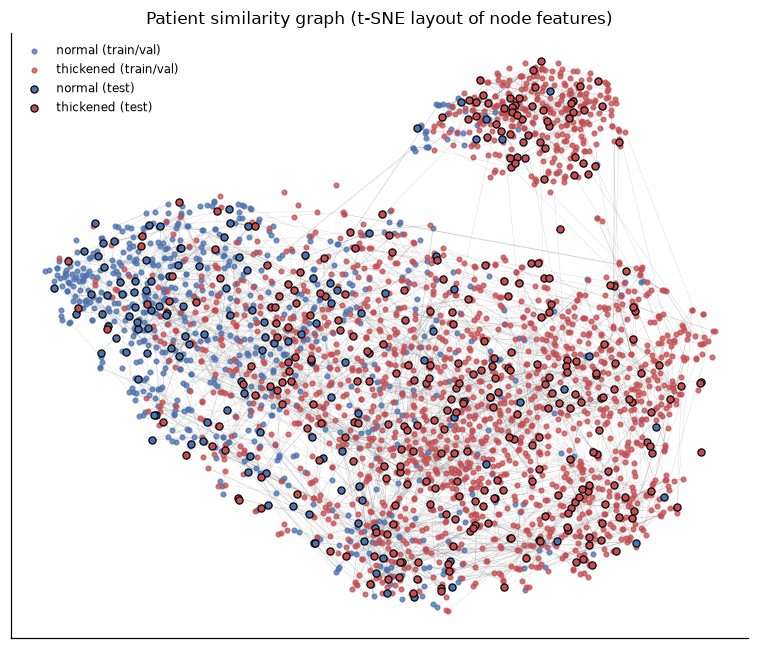

In [27]:
rng = np.random.RandomState(SEED)
xy = TSNE(n_components=2, perplexity=30, init="pca", random_state=SEED).fit_transform(x_np)

und = ei_np[:, ei_np[0] < ei_np[1]]
if und.shape[1] > 6000:
    und = und[:, rng.choice(und.shape[1], 6000, replace=False)]
segs = np.stack([xy[und[0]], xy[und[1]]], axis=1)

fig, ax = plt.subplots(figsize=(7, 6))
ax.add_collection(LineCollection(segs, colors="0.6", linewidths=0.3, alpha=0.35, zorder=1))
for c in (0, 1):
    m = (y_np == c) & ~test_np
    ax.scatter(xy[m, 0], xy[m, 1], s=9, c=LABEL_COL[c], alpha=0.75, label=f"{LABEL_NAME[c]} (train/val)", zorder=2)
for c in (0, 1):
    m = (y_np == c) & test_np
    ax.scatter(xy[m, 0], xy[m, 1], s=22, c=LABEL_COL[c], edgecolors="black", linewidths=0.8,
               label=f"{LABEL_NAME[c]} (test)", zorder=3)
ax.set_xticks([]); ax.set_yticks([])
ax.set_title("Patient similarity graph (t-SNE layout of node features)")
ax.legend(frameon=False, fontsize=8, loc="best")
plt.tight_layout(); save_fig("fig_patient_graph"); plt.show()

In [ ]:
store = {}
hook = model.gat2.register_forward_pre_hook(lambda m, args: store.__setitem__("h", args[0].detach().cpu().numpy()))
model.eval()
with torch.no_grad():
    _ = model(graph_data.x, graph_data.edge_index, graph_data.edge_attr)
hook.remove()
h_np = store["h"]

if "x_np" not in globals():
    x_np = graph_data.x.cpu().numpy()
if "y_np" not in globals():
    y_np = graph_data.y.cpu().numpy()
if "LABEL_COL" not in globals():
    C_NORMAL, C_THICK = "#4C72B0", "#C44E52"
    LABEL_COL = np.array([C_NORMAL, C_THICK])
    LABEL_NAME = ["normal", "thickened"]
if "save_fig" not in globals():
    def save_fig(name):
        os.makedirs("figures", exist_ok=True)
        plt.savefig(f"figures/{name}.png")
        plt.savefig(f"figures/{name}.pdf")
if "xy" not in globals():
    xy = TSNE(n_components=2, perplexity=30, init="pca", random_state=SEED).fit_transform(x_np)

xy_hid = TSNE(n_components=2, perplexity=30, init="pca", random_state=SEED).fit_transform(h_np)
sil_in  = silhouette_score(x_np, y_np)
sil_hid = silhouette_score(h_np, y_np)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))
for ax, pts, ttl, sil in [(axes[0], xy,     "Input features (ResNet embedding + age + gender)", sil_in),
                          (axes[1], xy_hid, "After GAT layer 1 (hidden representation)", sil_hid)]:
    for c in (0, 1):
        m = y_np == c
        ax.scatter(pts[m, 0], pts[m, 1], s=8, c=LABEL_COL[c], alpha=0.65, label=LABEL_NAME[c])
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(f"{ttl}\nsilhouette = {sil:.3f}", fontsize=10)
axes[0].legend(frameon=False, fontsize=8)
plt.tight_layout(); save_fig("fig_embedding_before_after"); plt.show()


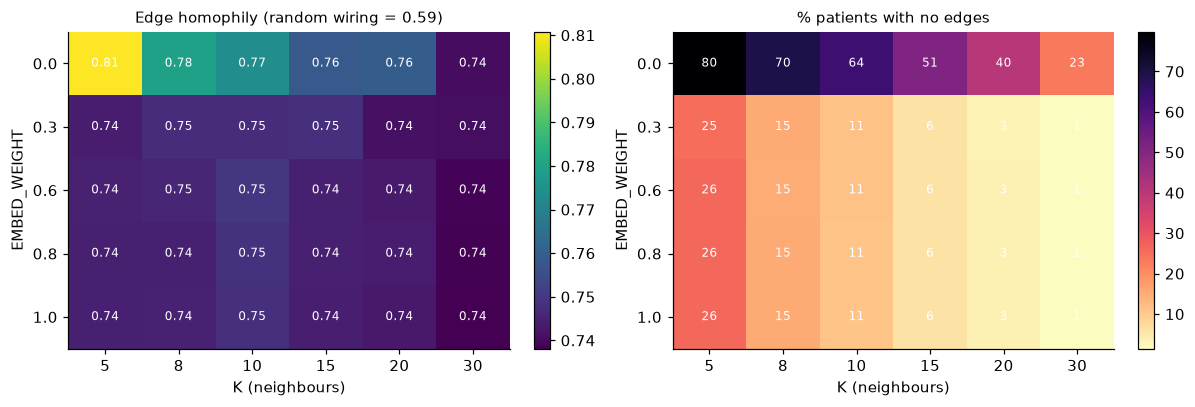

In [28]:
labels = patients_df["label"].values
p1 = labels.mean()
random_baseline = p1**2 + (1 - p1)**2

K_GRID = [5, 8, 10, 15, 20, 30]
W_GRID = [0.0, 0.3, 0.6, 0.8, 1.0]
homophily = np.full((len(W_GRID), len(K_GRID)), np.nan)
isolated  = np.full((len(W_GRID), len(K_GRID)), np.nan)

for wi, w in enumerate(W_GRID):
    comb = np.concatenate([np.sqrt(w) * embed_matrix_scaled,
                           np.sqrt(1 - w) * clinical_matrix_scaled], axis=1)
    idx_all = NearestNeighbors(n_neighbors=max(K_GRID) + 1).fit(comb).kneighbors(comb)[1]
    for ki, k in enumerate(K_GRID):
        nbr = idx_all[:, 1:k + 1]
        sets = [set(r) for r in nbr]
        same, total = 0, 0
        deg = np.zeros(N, dtype=int)
        for i in range(N):
            for j in nbr[i]:
                if i in sets[j]:
                    total += 1; same += int(labels[i] == labels[j])
                    deg[i] += 1
        homophily[wi, ki] = same / total if total else np.nan
        isolated[wi, ki]  = 100 * np.mean(deg == 0)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, mat, ttl, fmt, cmap in [(axes[0], homophily, f"Edge homophily (random wiring = {random_baseline:.2f})", "{:.2f}", "viridis"),
                                (axes[1], isolated,  "% patients with no edges", "{:.0f}", "magma_r")]:
    im = ax.imshow(mat, cmap=cmap, aspect="auto")
    ax.set_xticks(range(len(K_GRID))); ax.set_xticklabels(K_GRID); ax.set_xlabel("K (neighbours)")
    ax.set_yticks(range(len(W_GRID))); ax.set_yticklabels(W_GRID); ax.set_ylabel("EMBED_WEIGHT")
    ax.set_title(ttl, fontsize=10)
    for i in range(len(W_GRID)):
        for j in range(len(K_GRID)):
            ax.text(j, i, fmt.format(mat[i, j]), ha="center", va="center", color="white", fontsize=8)
    plt.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout(); save_fig("fig_graph_homophily_grid"); plt.show()

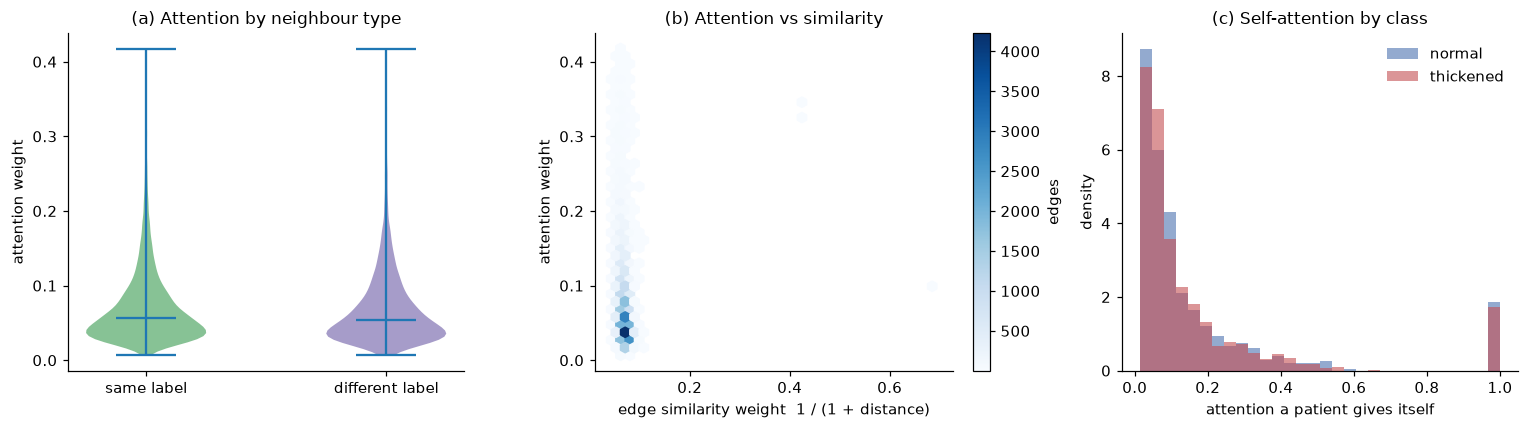

mean attention  same-label: 0.0747 | different-label: 0.0721


In [29]:
model.eval()
with torch.no_grad():
    _, (ei1, a1), _ = model(graph_data.x, graph_data.edge_index, graph_data.edge_attr, return_attention=True)
ei1_np = ei1.cpu().numpy()
att = a1.mean(dim=1).cpu().numpy()

assert np.array_equal(ei1_np[:, :E], ei_np), "edge order changed - check PyG version"
att_nb   = att[:E]
att_self = att[E:E + N]
src, dst = ei_np
same_lab = labels[src] == labels[dst]

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

ax = axes[0]
parts = ax.violinplot([att_nb[same_lab], att_nb[~same_lab]], showmedians=True)
for pc, col in zip(parts["bodies"], ["#55A868", "#8172B2"]):
    pc.set_facecolor(col); pc.set_alpha(0.7)
ax.set_xticks([1, 2]); ax.set_xticklabels(["same label", "different label"])
ax.set_ylabel("attention weight"); ax.set_title("(a) Attention by neighbour type")

ax = axes[1]
hb = ax.hexbin(ew_np, att_nb, gridsize=35, cmap="Blues", mincnt=1)
ax.set_xlabel("edge similarity weight  1 / (1 + distance)"); ax.set_ylabel("attention weight")
ax.set_title("(b) Attention vs similarity")
plt.colorbar(hb, ax=ax, fraction=0.046, label="edges")

ax = axes[2]
for c in (0, 1):
    ax.hist(att_self[y_np == c], bins=30, alpha=0.6, color=LABEL_COL[c], label=LABEL_NAME[c], density=True)
ax.set_xlabel("attention a patient gives itself"); ax.set_ylabel("density")
ax.set_title("(c) Self-attention by class"); ax.legend(frameon=False)

plt.tight_layout(); save_fig("fig_attention_analysis"); plt.show()
print(f"mean attention  same-label: {att_nb[same_lab].mean():.4f} | different-label: {att_nb[~same_lab].mean():.4f}")

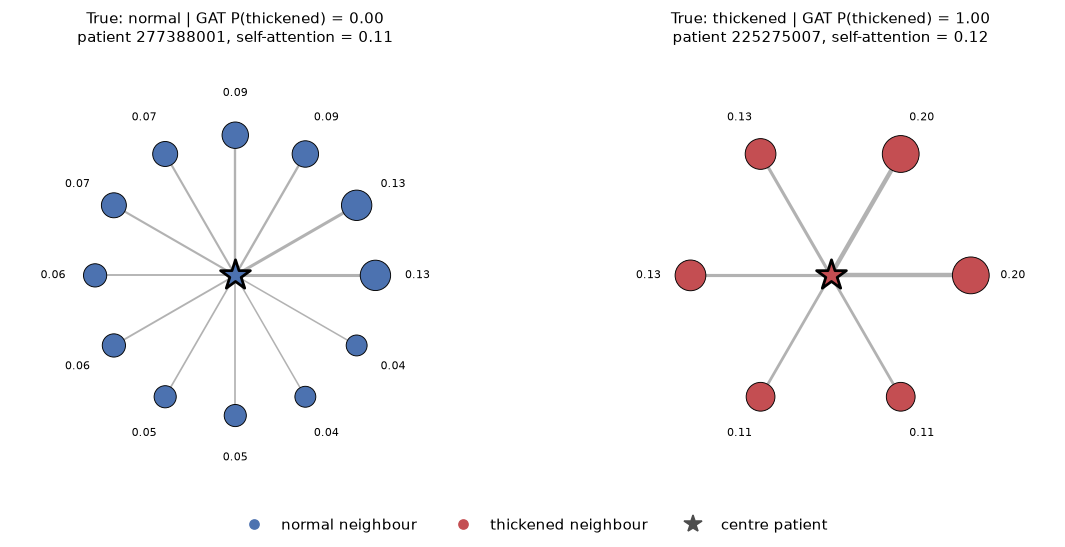

In [30]:
from matplotlib.lines import Line2D

gat_prob = all_probs
deg = np.bincount(dst, minlength=N)

def pick_example(cls, min_deg=5):
    cand = np.where(test_np & (y_np == cls) & (deg >= min_deg))[0]
    if len(cand) == 0:
        return None
    conf = gat_prob[cand] if cls == 1 else 1 - gat_prob[cand]
    return cand[np.argmax(conf)]

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, cls in zip(axes, (0, 1)):
    node = pick_example(cls)
    ax.set_aspect("equal"); ax.axis("off")
    if node is None:
        ax.set_title(f"no {LABEL_NAME[cls]} test patient with enough neighbours"); continue
    m = dst == node
    nbrs, a = src[m], att_nb[m]
    order = np.argsort(-a)[:12]
    nbrs, a = nbrs[order], a[order]
    ang = np.linspace(0, 2 * np.pi, len(nbrs), endpoint=False)
    px, py = np.cos(ang), np.sin(ang)
    for xi, yi, ai in zip(px, py, a):
        ax.plot([0, xi], [0, yi], color="0.5", lw=0.5 + 12 * ai, alpha=0.6, zorder=1)
    ax.scatter(px, py, s=80 + 2500 * a, c=LABEL_COL[labels[nbrs]], edgecolors="black", linewidths=0.6, zorder=2)
    ax.scatter([0], [0], s=420, c=LABEL_COL[cls], edgecolors="black", linewidths=1.8, marker="*", zorder=3)
    for xi, yi, ai in zip(px, py, a):
        ax.text(1.3 * xi, 1.3 * yi, f"{ai:.2f}", ha="center", va="center", fontsize=7)
    ax.set_xlim(-1.6, 1.6); ax.set_ylim(-1.6, 1.6)
    ax.set_title(f"True: {LABEL_NAME[cls]} | GAT P(thickened) = {gat_prob[node]:.2f}\n"
                 f"patient {patients_df.iloc[node]['patient_id']}, self-attention = {att_self[node]:.2f}", fontsize=10)

handles = [Line2D([], [], marker="o", ls="", color=C_NORMAL, label="normal neighbour"),
           Line2D([], [], marker="o", ls="", color=C_THICK,  label="thickened neighbour"),
           Line2D([], [], marker="*", ls="", color="0.3", markersize=12, label="centre patient")]
fig.legend(handles=handles, loc="lower center", ncol=3, frameon=False)
plt.tight_layout(rect=(0, 0.05, 1, 1)); save_fig("fig_ego_networks"); plt.show()

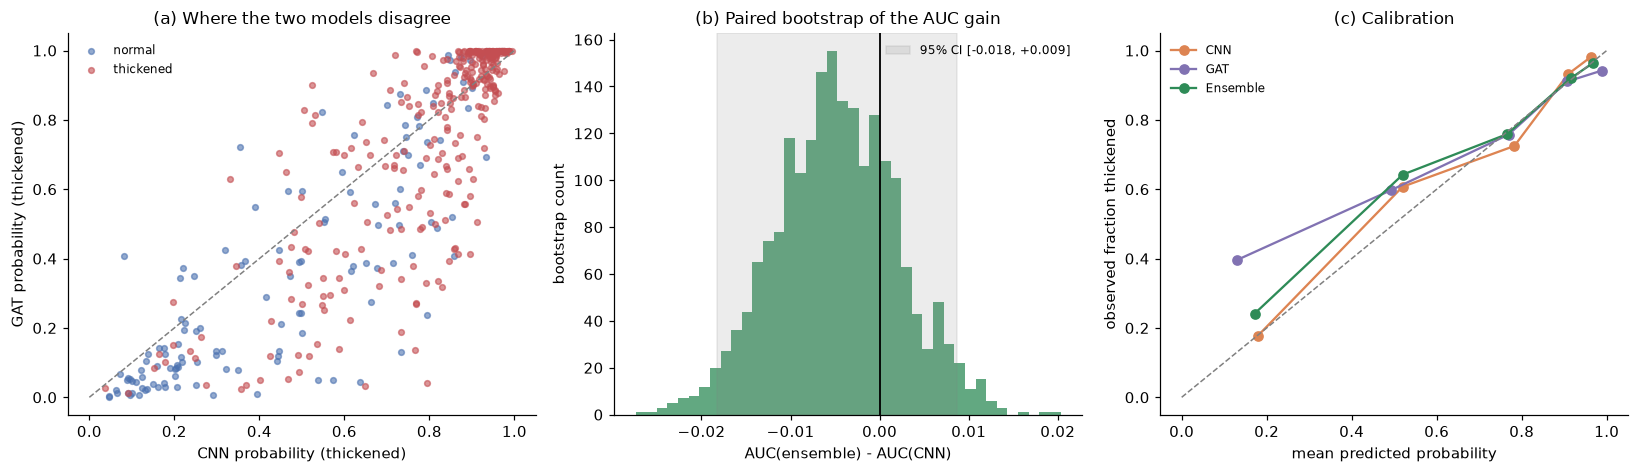

Ensemble - CNN AUC gain: -0.0048  (95% CI -0.0183 to +0.0086)
CI includes 0 -> gain not clearly distinguishable from noise


In [31]:
models_ = {"CNN": cnn_aligned, "GAT": y_prob, "Ensemble": ens_probs_test_final}
cols_   = {"CNN": "#DD8452", "GAT": "#8172B2", "Ensemble": "#2E8B57"}

fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))

ax = axes[0]
for c in (0, 1):
    m = y_true == c
    ax.scatter(cnn_aligned[m], y_prob[m], s=14, c=LABEL_COL[c], alpha=0.6, label=LABEL_NAME[c])
ax.plot([0, 1], [0, 1], "--", color="0.5", lw=1)
ax.set_xlabel("CNN probability (thickened)"); ax.set_ylabel("GAT probability (thickened)")
ax.set_title("(a) Where the two models disagree"); ax.legend(frameon=False, fontsize=8)

ax = axes[1]
rng = np.random.RandomState(SEED)
diffs = []
for _ in range(2000):
    ix = rng.randint(0, len(y_true), len(y_true))
    if len(np.unique(y_true[ix])) < 2:
        continue
    diffs.append(roc_auc_score(y_true[ix], ens_probs_test_final[ix]) - roc_auc_score(y_true[ix], cnn_aligned[ix]))
diffs = np.array(diffs)
lo, hi = np.percentile(diffs, [2.5, 97.5])
ax.hist(diffs, bins=40, color=cols_["Ensemble"], alpha=0.75)
ax.axvline(0, color="black", lw=1.2)
ax.axvspan(lo, hi, color="0.5", alpha=0.15, label=f"95% CI [{lo:+.3f}, {hi:+.3f}]")
ax.set_xlabel("AUC(ensemble) - AUC(CNN)"); ax.set_ylabel("bootstrap count")
ax.set_title("(b) Paired bootstrap of the AUC gain"); ax.legend(frameon=False, fontsize=8)

ax = axes[2]
bins = np.quantile(np.concatenate(list(models_.values())), np.linspace(0, 1, 6))
for name, p in models_.items():
    b = np.clip(np.digitize(p, bins[1:-1]), 0, 4)
    xs, ys = [], []
    for k in range(5):
        m = b == k
        if m.sum() >= 5:
            xs.append(p[m].mean()); ys.append(y_true[m].mean())
    ax.plot(xs, ys, marker="o", color=cols_[name], label=name)
ax.plot([0, 1], [0, 1], "--", color="0.5", lw=1)
ax.set_xlabel("mean predicted probability"); ax.set_ylabel("observed fraction thickened")
ax.set_title("(c) Calibration"); ax.legend(frameon=False, fontsize=8)

plt.tight_layout(); save_fig("fig_model_comparison"); plt.show()
print(f"Ensemble - CNN AUC gain: {diffs.mean():+.4f}  (95% CI {lo:+.4f} to {hi:+.4f})")
print("CI includes 0 (gain not significant)" if lo <= 0 <= hi else "CI excludes 0")

In [32]:
import copy, time
import pandas as pd
from torch_geometric.nn import GATConv
from sklearn.metrics import roc_auc_score, confusion_matrix

N_SEEDS      = 5          # repeat every variant with different seeds

N_NODES = len(patients_df)
X_ALL   = graph_data.x
EMB_DIM = embed_matrix.shape[1]          # first EMB_DIM columns = image embedding, last 2 = age, gender
Y       = graph_data.y
TR, VA, TE = graph_data.train_mask, graph_data.val_mask, graph_data.test_mask


class AblationGAT(nn.Module):
    """Same as PatientGAT, but each part can be switched off."""
    def __init__(self, in_dim, hidden, heads, dropout, use_skip=True, use_bn=True, use_edge_attr=True):
        super().__init__()
        self.dropout = dropout
        self.use_edge_attr = use_edge_attr
        ed = 1 if use_edge_attr else None
        self.gat1 = GATConv(in_dim, hidden, heads=heads, dropout=dropout, edge_dim=ed)
        self.bn1 = nn.BatchNorm1d(hidden * heads) if use_bn else nn.Identity()
        self.gat2 = GATConv(hidden * heads, 2, heads=1, concat=False, dropout=dropout, edge_dim=ed)
        self.skip_proj = nn.Linear(in_dim, hidden * heads) if use_skip else None

    def forward(self, x, ei, ea):
        ea = ea if self.use_edge_attr else None
        x_in = x
        x = F.dropout(x, p=self.dropout, training=self.training)
        h = F.elu(self.bn1(self.gat1(x, ei, edge_attr=ea)))
        if self.skip_proj is not None:
            h = h + self.skip_proj(x_in)
        h = F.dropout(h, p=self.dropout, training=self.training)
        return self.gat2(h, ei, edge_attr=ea)


def build_graph(k=K_NEIGHBORS, w=EMBED_WEIGHT, mutual=True):
    # Build graph with configurable k, embed weight, and mutual-NN option.
    comb = np.concatenate([np.sqrt(w) * embed_matrix_scaled,
                           np.sqrt(1 - w) * clinical_matrix_scaled], axis=1)
    dist, idx = NearestNeighbors(n_neighbors=k + 1).fit(comb).kneighbors(comb)
    nsets = [set(r[1:]) for r in idx]
    el, wl = [], []
    for i in range(len(comb)):
        for pos, j in enumerate(idx[i][1:]):
            if mutual and i not in nsets[j]:
                continue
            wt = 1.0 / (1.0 + dist[i][pos + 1])
            el.append((i, j)); wl.append(wt)
            el.append((j, i)); wl.append(wt)
    ei = torch.tensor(el, dtype=torch.long).t().contiguous().to(device)
    ea = torch.tensor(wl, dtype=torch.float).unsqueeze(-1).to(device)
    return ei, ea


def random_graph_like(ei, ea, seed=0):
    g = torch.Generator().manual_seed(seed)
    n_pairs = ei.shape[1] // 2
    a = torch.randint(0, N_NODES, (n_pairs,), generator=g)
    b = torch.randint(0, N_NODES, (n_pairs,), generator=g)
    keep = a != b
    a, b = a[keep], b[keep]
    ei_r = torch.stack([torch.cat([a, b]), torch.cat([b, a])]).to(device)
    ea_r = torch.full((ei_r.shape[1], 1), float(ea.mean()), device=device)
    return ei_r, ea_r


def train_variant(x, ei, ea, cfg, seed):
    torch.manual_seed(seed); np.random.seed(seed)
    mdl = AblationGAT(x.shape[1], GAT_HIDDEN, cfg.get("heads", GAT_HEADS), GAT_DROPOUT,
                      use_skip=cfg.get("skip", True), use_bn=cfg.get("bn", True),
                      use_edge_attr=cfg.get("edge_attr", True)).to(device)
    counts = torch.bincount(Y[TR])
    cw = 1.0 / torch.sqrt(counts.float())
    cw = (cw / cw.sum() * 2).to(device)
    crit = nn.CrossEntropyLoss(weight=cw)

    best_val, best_state, bad = float("inf"), None, 0
    for ep in range(ABL_EPOCHS):
        mdl.train(); opt.zero_grad()
        loss = crit(mdl(x, ei, ea)[TR], Y[TR])
        loss.backward()
        torch.nn.utils.clip_grad_norm_(mdl.parameters(), max_norm=1.0)
        opt.step(); sch.step()
        mdl.eval()
        with torch.no_grad():
            vl = crit(mdl(x, ei, ea)[VA], Y[VA]).item()
        if vl < best_val:
            best_val, best_state, bad = vl, copy.deepcopy(mdl.state_dict()), 0
        else:
            bad += 1
            if bad >= ABL_PATIENCE:
                break
    mdl.load_state_dict(best_state); mdl.eval()
    with torch.no_grad():
        return F.softmax(mdl(x, ei, ea), dim=1)[:, 1].cpu().numpy()


def score_probs(p):
    """AUC on val and test; threshold chosen on VAL only (best balanced accuracy)."""
    va, te = VA.cpu().numpy(), TE.cpu().numpy()
    yv, pv = Y.cpu().numpy()[va], p[va]
    yt, pt = Y.cpu().numpy()[te], p[te]
    best_t, best_ba = 0.5, -1
    for t in np.arange(0.20, 0.81, 0.01):
        tn, fp, fn, tp = confusion_matrix(yv, (pv >= t).astype(int), labels=[0, 1]).ravel()
        ba = 0.5 * (tp / max(tp + fn, 1) + tn / max(tn + fp, 1))
        if ba > best_ba:
            best_ba, best_t = ba, t
    tn, fp, fn, tp = confusion_matrix(yt, (pt >= best_t).astype(int), labels=[0, 1]).ravel()
    return {"val_auc": roc_auc_score(yv, pv), "test_auc": roc_auc_score(yt, pt),
            "test_bal_acc": 0.5 * (tp / max(tp + fn, 1) + tn / max(tn + fp, 1))}

In [33]:
EI_FULL, EA_FULL = graph_data.edge_index, graph_data.edge_attr
graph_cache = {}

def get_graph(spec):
    if spec not in graph_cache:
        if spec[0] == "full":
            graph_cache[spec] = (EI_FULL, EA_FULL)
        elif spec[0] == "none":
            graph_cache[spec] = (torch.empty((2, 0), dtype=torch.long, device=device), None)
        elif spec[0] == "random":
            graph_cache[spec] = random_graph_like(EI_FULL, EA_FULL)
        elif spec[0] == "knn":
            graph_cache[spec] = build_graph(k=spec[1], w=spec[2], mutual=spec[3])
    return graph_cache[spec]

def get_x(kind):
    if kind == "img":  return X_ALL[:, :EMB_DIM]
    if kind == "clin": return X_ALL[:, EMB_DIM:]
    return X_ALL

# (name, group, node features, graph, model options)
VARIANTS = [
    ("Full model (reference)",           "reference",    "both", ("full",), {}),
    ("Image embedding only",             "features",     "img",  ("full",), {}),
    ("Age + gender only",                "features",     "clin", ("full",), {}),
    ("No graph (self-loops only)",       "graph",        "both", ("none",), {"edge_attr": False}),
    ("Random graph (same size)",         "graph",        "both", ("random",), {}),
    ("Non-mutual k-NN (K=15)",           "graph",        "both", ("knn", K_NEIGHBORS, EMBED_WEIGHT, False), {}),
    ("Mutual k-NN, K=8",                 "graph",        "both", ("knn", 8, EMBED_WEIGHT, True), {}),
    ("Mutual k-NN, K=30",                "graph",        "both", ("knn", 30, EMBED_WEIGHT, True), {}),
    ("Graph from image only (w=1)",      "graph",        "both", ("knn", K_NEIGHBORS, 1.0, True), {}),
    ("Graph from age+gender only (w=0)", "graph",        "both", ("knn", K_NEIGHBORS, 0.0, True), {}),
    ("No edge weights",                  "architecture", "both", ("full",), {"edge_attr": False}),
    ("No skip connection",               "architecture", "both", ("full",), {"skip": False}),
    ("No BatchNorm",                     "architecture", "both", ("full",), {"bn": False}),
    ("1 attention head",                 "architecture", "both", ("full",), {"heads": 1}),
]

rows = []
for name, group, feats, gspec, cfg in VARIANTS:
    t0 = time.time()
    x_v = get_x(feats)
    ei_v, ea_v = get_graph(gspec)
    for s in range(N_SEEDS):
        probs = train_variant(x_v, ei_v, ea_v, cfg, seed=SEED + s)
        rows.append({"variant": name, "group": group, "seed": SEED + s, **score_probs(probs)})
    r = pd.DataFrame(rows)
    r = r[r.variant == name]
    print(f"{name:38s} test AUC {r.test_auc.mean():.4f} ± {r.test_auc.std():.4f}   ({time.time()-t0:.0f}s)")

results_df = pd.DataFrame(rows)
results_df.to_csv("ablation_raw_results.csv", index=False)

Full model (reference)                 test AUC 0.7981 ± 0.0150   (175s)
Image embedding only                   test AUC 0.7939 ± 0.0103   (206s)
Age + gender only                      test AUC 0.8626 ± 0.0008   (377s)
No graph (self-loops only)             test AUC 0.7998 ± 0.0081   (68s)
Random graph (same size)               test AUC 0.5541 ± 0.0387   (336s)
Non-mutual k-NN (K=15)                 test AUC 0.8194 ± 0.0104   (414s)
Mutual k-NN, K=8                       test AUC 0.7954 ± 0.0100   (104s)
Mutual k-NN, K=30                      test AUC 0.7991 ± 0.0104   (285s)
Graph from image only (w=1)            test AUC 0.8016 ± 0.0118   (11559s)
Graph from age+gender only (w=0)       test AUC 0.8245 ± 0.0140   (324s)
No edge weights                        test AUC 0.7998 ± 0.0100   (134s)
No skip connection                     test AUC 0.8189 ± 0.0035   (156s)
No BatchNorm                           test AUC 0.8141 ± 0.0115   (177s)
1 attention head                       test AUC 0.

                         variant        group  val_auc  test_auc  test_auc_std  test_bal_acc  test_bal_acc_std  delta_vs_full
          Full model (reference)    reference   0.8231    0.7981        0.0150        0.7253            0.0088         0.0000
            Image embedding only     features   0.8299    0.7939        0.0103        0.7219            0.0114        -0.0041
               Age + gender only     features   0.8392    0.8626        0.0008        0.7577            0.0055         0.0646
      No graph (self-loops only)        graph   0.7932    0.7998        0.0081        0.7088            0.0094         0.0018
        Random graph (same size)        graph   0.6294    0.5541        0.0387        0.5410            0.0404        -0.2439
          Non-mutual k-NN (K=15)        graph   0.8297    0.8194        0.0104        0.7366            0.0132         0.0213
                Mutual k-NN, K=8        graph   0.8236    0.7954        0.0100        0.7204            0.0078        

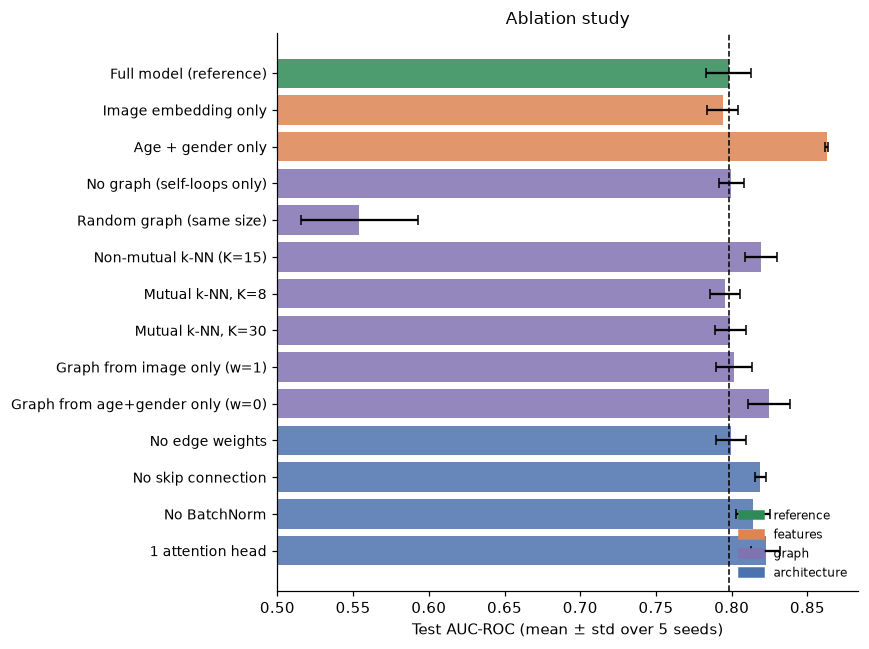

In [34]:
summary = (results_df.groupby(["variant", "group"], sort=False)
           .agg(val_auc=("val_auc", "mean"),
                test_auc=("test_auc", "mean"), test_auc_std=("test_auc", "std"),
                test_bal_acc=("test_bal_acc", "mean"), test_bal_acc_std=("test_bal_acc", "std"))
           .reset_index())
ref = summary.loc[summary.variant == "Full model (reference)", "test_auc"].iloc[0]
summary["delta_vs_full"] = summary["test_auc"] - ref

print(summary.round(4).to_string(index=False))
summary.to_csv("ablation_summary.csv", index=False)

GROUP_COL = {"reference": "#2E8B57", "features": "#DD8452", "graph": "#8172B2", "architecture": "#4C72B0"}
fig, ax = plt.subplots(figsize=(8, 6))
ypos = np.arange(len(summary))[::-1]
ax.barh(ypos, summary["test_auc"], xerr=summary["test_auc_std"], capsize=3,
        color=[GROUP_COL[g] for g in summary["group"]], alpha=0.85)
ax.axvline(ref, color="black", lw=1, ls="--")
ax.set_yticks(ypos); ax.set_yticklabels(summary["variant"], fontsize=9)
lo = max(0.5, (summary["test_auc"] - summary["test_auc_std"]).min() - 0.02)
ax.set_xlim(lo, min(1.0, (summary["test_auc"] + summary["test_auc_std"]).max() + 0.02))
ax.set_xlabel(f"Test AUC-ROC (mean ± std over {N_SEEDS} seeds)")
ax.set_title("Ablation study")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=c, label=g) for g, c in GROUP_COL.items()],
          frameon=False, fontsize=8, loc="lower right")
plt.tight_layout(); plt.savefig("figures/fig_ablation.png"); plt.savefig("figures/fig_ablation.pdf"); plt.show()

In [35]:
if "cnn_val_aligned" not in globals():
    cnn_val_probs_img = np.load("cnn_val_probs.npy")
    cnn_val_pids_img = pd.read_csv("cnn_val_probs_pids.csv")["patient_id"].astype(str).values
    cnn_val_df = pd.DataFrame({"patient_id": cnn_val_pids_img, "cnn_prob": cnn_val_probs_img})
    cnn_val_patient_probs = cnn_val_df.groupby("patient_id")["cnn_prob"].mean()
    val_pids_ordered = patients_df.iloc[np.where(val_idx)[0]]["patient_id"].values
    cnn_val_aligned = cnn_val_patient_probs.loc[val_pids_ordered].values
    gat_val_probs = y_prob_val
    ens_val_labels = y_true_val
    n = min(len(cnn_val_aligned), len(gat_val_probs))

def pick_thr(yv, pv):
    best_t, best_ba = 0.5, -1
    for t in np.arange(0.20, 0.81, 0.01):
        tn, fp, fn, tp = confusion_matrix(yv, (pv >= t).astype(int), labels=[0, 1]).ravel()
        ba = 0.5 * (tp / max(tp + fn, 1) + tn / max(tn + fp, 1))
        if ba > best_ba:
            best_ba, best_t = ba, t
    return best_t

cnn_v, gat_v, yv_ens = cnn_val_aligned[:n], gat_val_probs[:n], ens_val_labels

# choose the ensemble weight on VALIDATION AUC (not test)
w_grid = np.round(np.arange(0.0, 1.001, 0.05), 2)
val_aucs = [roc_auc_score(yv_ens, (1 - w) * cnn_v + w * gat_v) for w in w_grid]
w_star = float(w_grid[int(np.argmax(val_aucs))])
print(f"Ensemble weight chosen on validation: w_gat = {w_star:.2f}")

rng = np.random.RandomState(SEED)
boot_idx = [rng.randint(0, len(y_true), len(y_true)) for _ in range(1000)]

rows_e = []
for name, w in [("CNN only", 0.0), ("GAT only", 1.0), (f"Ensemble (w_gat={w_star:.2f})", w_star)]:
    pv_ = (1 - w) * cnn_v + w * gat_v
    pt_ = (1 - w) * cnn_aligned + w * y_prob
    t = pick_thr(yv_ens, pv_)
    tn, fp, fn, tp = confusion_matrix(y_true, (pt_ >= t).astype(int), labels=[0, 1]).ravel()
    aucs = [roc_auc_score(y_true[ix], pt_[ix]) for ix in boot_idx if len(np.unique(y_true[ix])) == 2]
    rows_e.append({"model": name, "threshold (val)": round(t, 2),
                   "test AUC": roc_auc_score(y_true, pt_),
                   "AUC 95% CI": f"{np.percentile(aucs, 2.5):.3f} - {np.percentile(aucs, 97.5):.3f}",
                   "accuracy": (tp + tn) / (tp + tn + fp + fn),
                   "sensitivity": tp / max(tp + fn, 1),
                   "specificity": tn / max(tn + fp, 1)})

ens_table = pd.DataFrame(rows_e)
print(ens_table.round(4).to_string(index=False))
ens_table.to_csv("ablation_ensemble.csv", index=False)


Ensemble weight chosen on validation: w_gat = 0.25
                model  threshold (val)  test AUC    AUC 95% CI  accuracy  sensitivity  specificity
             CNN only             0.67    0.8480 0.811 - 0.885    0.7638       0.7922       0.6953
             GAT only             0.41    0.8195 0.779 - 0.858    0.7821       0.8377       0.6484
Ensemble (w_gat=0.25)             0.65    0.8477 0.810 - 0.884    0.7638       0.7792       0.7266
